# Прогноз по доходам и расходам

## Кому звонить: логистическая регрессия, которая максимизирует прибыль банковской кампании

Телефонный маркетинг срочного депозита, [UCI Bank Marketing](https://archive.ics.uci.edu/ml/datasets/bank+marketing).

Звонок стоит **$2**, согласие на срочный депозит приносит **$10**. Звоним только тем, кого модель отнесла к положительному классу.

Целевая переменная — согласие клиента.


**Почему прибыль, а не ROC-AUC.** AUC отвечает только за то, насколько хорошо модель *ранжирует* клиентов по склонности согласиться. Он ничего не знает ни про цену звонка и депозита, ни про то, где проведён порог, ни про долю согласий. А ошибки здесь неравноценны: лишний звонок отказнику — минус $2, пропущенный согласившийся — минус $10 недополученной выручки. Поэтому важно не только правильно упорядочить людей, но и решить, **где провести границу звонка**. Порог классификации выбирается по прибыли.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams["axes.unicode_minus"] = False


## Данные

Загружаем датасет, смотрим размер и долю согласий. `duration` сразу убираем из признаков — он известен только после звонка и в проде недоступен.


In [2]:
df = pd.read_csv("bank-additional/bank-additional-full.csv", sep=";")
print(f"Контактов: {len(df)}, доля согласий: {(df.y == 'yes').mean():.1%}")
display(df.drop(columns="duration").head(3))


Контактов: 41188, доля согласий: 11.3%


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Согласий 11.3% — классы несбалансированы. Поэтому далее оценка стратифицированная (StratifiedKFold). Порог 0.5 при такой базе почти наверняка неоптимален — его будем подбирать по прибыли.

## Корреляции числовых признаков

Прежде чем строить модель, посмотрим на корреляции: если часть признаков — один и тот же сигнал, коэффициенты при них будут нестабильны, и интерпретировать их по отдельности нельзя.

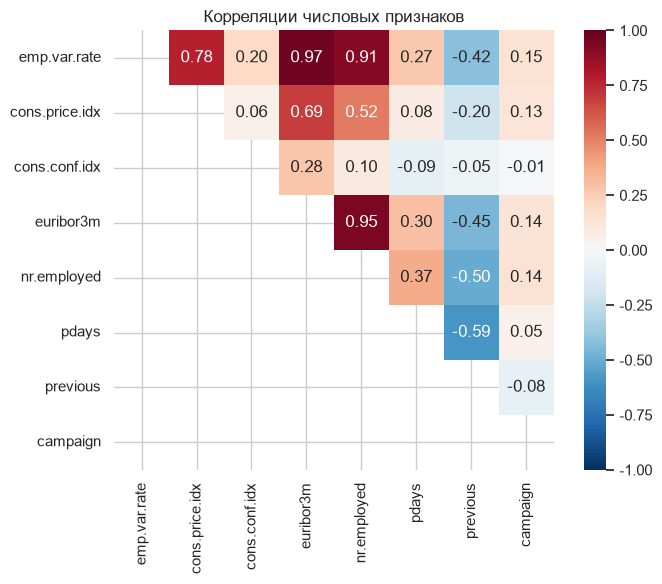

In [24]:
num_for_corr = [
    "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m",
    "nr.employed", "pdays", "previous", "campaign",
]
corr = df[num_for_corr].corr()

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
mask = ~mask

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", mask=mask,cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Корреляции числовых признаков")
fig.tight_layout()
fig.savefig("images/corr_heatmap.png", dpi=150, bbox_inches="tight")

Виден блок из трёх почти идентичных рядов: `emp.var.rate`, `euribor3m`, `nr.employed` коррелированы на **0.91–0.97** — это один сигнал «состояние экономики», разложенный на три столбца. 

Посмотрим, как каждый признак связан с целевой отдельно:


In [26]:
y_num = (df.y == "yes").astype(int)
target_corr = df[num_for_corr].corrwith(y_num).sort_values()
display(target_corr.round(3).to_frame("corr_with_y"))

,corr_with_y
nr.employed,-0.355
pdays,-0.325
euribor3m,-0.308
emp.var.rate,-0.298
cons.price.idx,-0.136
campaign,-0.066
cons.conf.idx,0.055
previous,0.230


Внутри ядра связи с целевой почти одинаковые: `nr.employed` (−0.355), `euribor3m` (−0.308), `emp.var.rate` (−0.298). Оставим один, наиболее интерпретируемый - `nr.employed`

## Препроцессинг и базовая модель

Категории кодируем one-hot, числа стандартизуем. Метрики качества — ROC-AUC и average precision (AP): первая смотрит на ранжирование целиком, вторая чувствительна к редкому положительному классу. Оценка — стратифицированная кросс-валидация на 5 фолдов: модель обучается на четырёх, предсказывает на пятом, и так по кругу. Это даёт out-of-fold прогнозы, по которым ниже считаются метрики и прибыль.


In [58]:
drop_num = ["euribor3m", "emp.var.rate"]
X = df.drop(columns=["duration", "y"]+ drop_num)
y = df.y == "yes"

cat_cols = X.select_dtypes(include="str").columns.tolist()
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
encoder = ColumnTransformer([
    ("cats", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("nums", StandardScaler(), num_cols),
])
encoded = pd.DataFrame(
    encoder.fit_transform(X),
    columns=encoder.get_feature_names_out(),
)


def out_of_fold(X, y, C=1.0, random_state=42):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    parts = []
    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y)):
        model = LogisticRegression(C=C, max_iter=1000)
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        parts.append(pd.DataFrame({
            "fold": fold,
            "y": y.iloc[test_idx].to_numpy(),
            "proba": model.predict_proba(X.iloc[test_idx])[:, 1],
        }))
    return pd.concat(parts, ignore_index=True)


def call_profit(y_true, proba, threshold=0.5, random_revenue=False):
    y_true = np.asarray(y_true).astype(int)
    call = np.asarray(proba) > threshold
    subscribed = int((call & (y_true == 1)).sum())
    calls = int(call.sum())
    if random_revenue and subscribed:
        revenue = float(np.random.uniform(0, 20, subscribed).sum())
    else:
        revenue = 10 * subscribed
    expenses = 2 * calls
    return revenue - expenses, expenses


def evaluate(predictions, threshold=0.5, random_revenue=False):
    rows = []
    for _, group in predictions.groupby("fold"):
        profit, expenses = call_profit(group.y, group.proba, threshold, random_revenue)
        call = group.proba.to_numpy() > threshold
        rows.append({
            "roc_auc": roc_auc_score(group.y, group.proba),
            "average_precision": average_precision_score(group.y, group.proba),
            "precision": precision_score(group.y, call, zero_division=0),
            "recall": recall_score(group.y, call, zero_division=0),
            "profit": profit,
            "expenses": expenses,
        })
    return pd.DataFrame(rows)


baseline_pred = out_of_fold(encoded, y)
baseline = evaluate(baseline_pred)
display(baseline.round(3))


,roc_auc,average_precision,precision,recall,profit,expenses
0,0.783,0.432,0.633,0.200,1272,588
1,0.785,0.421,0.675,0.237,1548,652
2,0.801,0.480,0.689,0.277,1824,746
3,0.787,0.447,0.654,0.228,1472,648
4,0.786,0.450,0.671,0.218,1418,602


## Прибыль базовой модели

Оператору платим 2 доллара за каждый звонок. Депозит приносит 10 долларов.
Прибыль фолда = `10 * TP − 2 * (TP + FP)`.


Считаем среднюю прибыль, разброс по фолдам и расходы на операторов. Затем проверяем, насколько прибыль связана с обычными метриками качества: если связь слабая или нестабильная, выбирать модель по AUC рискованно.

In [28]:
print(f"Средняя прибыль на фолд: {baseline.profit.mean():.0f} $")
print(f"Стандартное отклонение: {baseline.profit.std(ddof=1):.0f} $")
print(f"Средний расход на операторов: {baseline.expenses.mean():.0f} $")

for column in ("roc_auc", "average_precision"):
    r, pvalue = stats.pearsonr(baseline[column], baseline.profit)
    print(f"{column}: r = {r:.2f}, p = {pvalue:.2f}")


Средняя прибыль на фолд: 1507 $
Стандартное отклонение: 204 $
Средний расход на операторов: 647 $
roc_auc: r = 0.91, p = 0.03
average_precision: r = 0.69, p = 0.19


По пяти фолдам связь прибыли с ROC-AUC и average precision но незначимая.
Дальше модель выбираем по прибыли.

## Коэффициент регуляризации

Ищем `C` по средней случайной прибыли. Сетку запускаем три раза с разными разбиениями на фолды.


seed 42: лучший C = 10
seed 777: лучший C = 100
seed 123: лучший C = 100


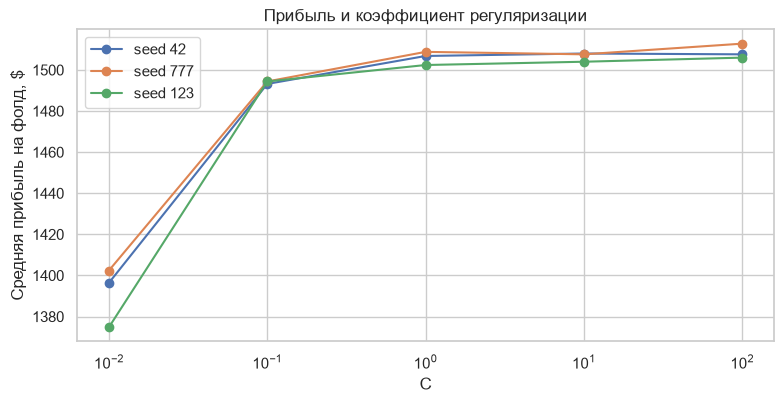

In [29]:
C_grid = np.logspace(-2, 2, 5)
seeds = (42, 777, 123)

fig, ax = plt.subplots(figsize=(8, 4.2))
best_C = {}
for seed in seeds:
    means = []
    for C in C_grid:
        pred = out_of_fold(encoded, y, C=float(C), random_state=seed)
        means.append(evaluate(pred).profit.mean())
    best_C[seed] = C_grid[int(np.argmax(means))]
    ax.plot(C_grid, means, marker="o", label=f"seed {seed}")

ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("Средняя прибыль на фолд, $")
ax.set_title("Прибыль и коэффициент регуляризации")
ax.legend(frameon=True)
fig.tight_layout()
fig.savefig("images/C_curve.png", dpi=150, bbox_inches="tight")

for seed, C in best_C.items():
    print(f"seed {seed}: лучший C = {C:g}")


Лучший `C` от запуска к запуску меняется, кривая почти плоская от C = 1 до C = 100. Подбор регуляризации почти не увеличивает прибыль.


## Порог бинаризации

Для этой цены звонка важнее полнота, чем точность: пропущенный клиент стоит дороже лишнего звонка.
Порог снижаем и смотрим, растёт ли прибыль. Сетка от 0 до 1 с шагом 0.01.


Лучший порог около **0.2**: полнота вырастает, точность падает, прибыль растёт.


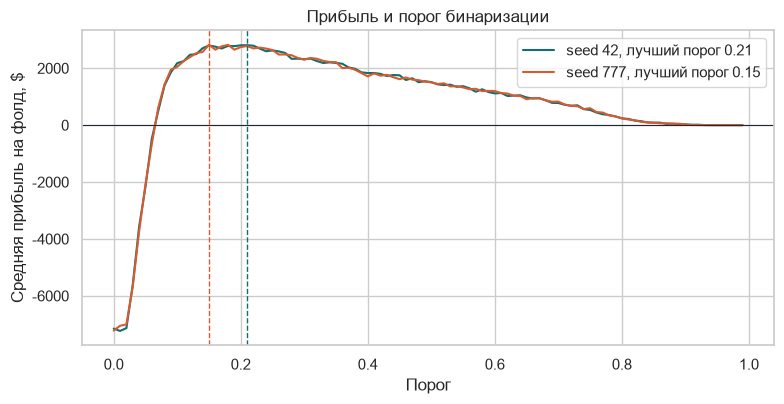

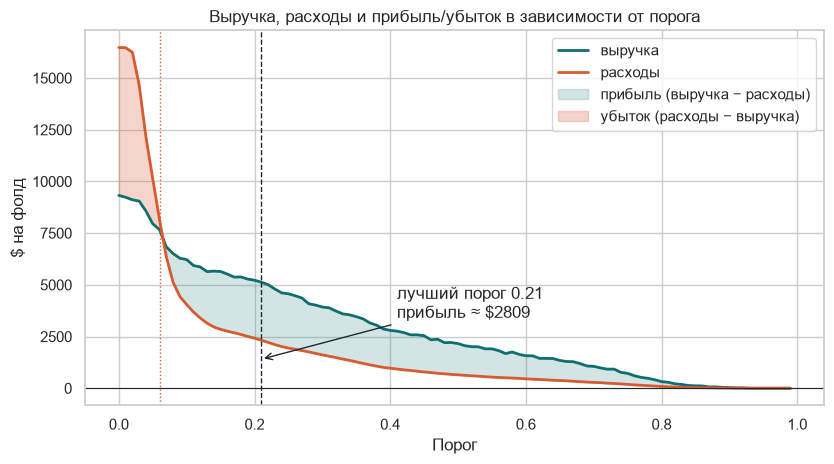

In [53]:
thresholds = np.round(np.arange(0, 1, 0.01), 2)

def threshold_curve(random_state, C=100.0):
    pred = out_of_fold(encoded, y, C=C, random_state=random_state)
    profits, expenses = [], []
    for threshold in thresholds:
        ev = evaluate(pred, threshold=threshold, random_revenue=True)
        profits.append(ev.profit.mean())
        expenses.append(ev.expenses.mean())
    profits = np.array(profits)
    expenses = np.array(expenses)
    return pred, profits, expenses

# --- данные ---
pred_42, profit_42, expense_42 = threshold_curve(42)
pred_777, profit_777, expense_777 = threshold_curve(777)
revenue_42 = profit_42 + expense_42
revenue_777 = profit_777 + expense_777

best_42 = thresholds[int(profit_42.argmax())]
best_777 = thresholds[int(profit_777.argmax())]

# точка безубыточности для seed 42: где прибыль меняет знак
sign_change = np.where(np.diff(np.sign(profit_42)) != 0)[0]
breakeven_42 = thresholds[sign_change[0]] if len(sign_change) else None

# --- фигура 1: прибыль и порог, два seed'а ---
fig1, ax1 = plt.subplots(figsize=(8, 4.2))
ax1.plot(thresholds, profit_42, color="#0F6E6E",
         label=f"seed 42, лучший порог {best_42:.2f}")
ax1.fill_between(thresholds, profit_42 - profit_42.std() * 0, profit_42, alpha=0)  # заглушка, чтобы не тянуть std
ax1.plot(thresholds, profit_777, color="#D85A30",
         label=f"seed 777, лучший порог {best_777:.2f}")
ax1.axvline(best_42, color="#0F6E6E", linestyle="--", linewidth=1)
ax1.axvline(best_777, color="#D85A30", linestyle="--", linewidth=1)
ax1.axhline(0, color="#1F2933", linewidth=0.8)
ax1.set_xlabel("Порог")
ax1.set_ylabel("Средняя прибыль на фолд, $")
ax1.set_title("Прибыль и порог бинаризации")
ax1.legend(frameon=True)
fig1.tight_layout()
fig1.savefig("images/threshold_curve.png", dpi=150, bbox_inches="tight")

# --- фигура 2: выручка, расходы, прибыль/убыток (seed 42) ---
fig2, ax2 = plt.subplots(figsize=(8.5, 4.8))
ax2.plot(thresholds, revenue_42, color="#0F6E6E", linewidth=2, label="выручка")
ax2.plot(thresholds, expense_42, color="#D85A30", linewidth=2, label="расходы")
ax2.fill_between(thresholds, expense_42, revenue_42,
                 where=revenue_42 >= expense_42, color="#0F6E6E", alpha=0.18,
                 label="прибыль (выручка − расходы)")
ax2.fill_between(thresholds, expense_42, revenue_42,
                 where=revenue_42 < expense_42, color="#D85A30", alpha=0.25,
                 label="убыток (расходы − выручка)")
ax2.axhline(0, color="#1F2933", linewidth=0.8)

ax2.axvline(best_42, color="#1F2933", linestyle="--", linewidth=1)
ax2.annotate(f"лучший порог {best_42:.2f}\nприбыль ≈ ${profit_42.max():.0f}",
             xy=(best_42, profit_42.max() / 2),
             xytext=(best_42 + 0.2, profit_42.max() / 2 + 2000),
             arrowprops=dict(arrowstyle="->", color="#1F2933"))

if breakeven_42 is not None:
    ax2.axvline(breakeven_42, color="#D85A30", linestyle=":", linewidth=1)
    
ax2.set_xlabel("Порог")
ax2.set_ylabel("$ на фолд")
ax2.set_title("Выручка, расходы и прибыль/убыток в зависимости от порога")
ax2.legend(frameon=True, loc="upper right")
fig2.tight_layout()
fig2.savefig("images/threshold_curve_money.png", dpi=150, bbox_inches="tight")



## Дефолтная модель и настроенная

Дефолт: `C = 1`, порог 0.5. Настроенная: `C = 100`, порог около 0.2.
Сравниваем прибыль по фолдам парным t-критерием.


In [60]:
default_eval = evaluate(out_of_fold(encoded, y, C=1.0, random_state=42),
                        threshold=0.5, random_revenue=True)
tuned_eval = evaluate(out_of_fold(encoded, y, C=100, random_state=42),
                      threshold=0.2, random_revenue=True)

summary = pd.DataFrame({
    "дефолт (C=1, порог 0.5)": {
        "прибыль, $": default_eval.profit.mean(),
        "std прибыли, $": default_eval.profit.std(ddof=1),
        "расходы, $": default_eval.expenses.mean(),
        "выручка, $": (default_eval.profit + default_eval.expenses).mean(),
        "звонков на фолд": (default_eval.expenses / 2).mean(),
    },
    "настроенная (C=100, порог 0.2)": {
        "прибыль, $": tuned_eval.profit.mean(),
        "std прибыли, $": tuned_eval.profit.std(ddof=1),
        "расходы, $": tuned_eval.expenses.mean(),
        "выручка, $": (tuned_eval.profit + tuned_eval.expenses).mean(),
        "звонков на фолд": (tuned_eval.expenses / 2).mean(),
    },
}).round(0)
display(summary)

t_stat, p_value = stats.ttest_rel(tuned_eval.profit, default_eval.profit)
print(f"парный t-критерий по прибыли: t = {t_stat:.2f}, p = {p_value:.4f}")



,"дефолт (C=1, порог 0.5)","настроенная (C=100, порог 0.2)"
"прибыль, $",1437.0,2852.0
"std прибыли, $",182.0,280.0
"расходы, $",647.0,2418.0
"выручка, $",2084.0,5270.0
звонков на фолд,324.0,1209.0


парный t-критерий по прибыли: t = 11.49, p = 0.0003


Прибыль настроенной модели выше на каждом фолде, отличие значимо (p ≈ 0.0002). Средний прирост — примерно с $1 500 до $2 800 на фолд.


## Какие признаки важны?

Коэффициенты той же логистической регрессии при `C = 100`. Плюс — выше шанс открыть депозит, минус — ниже. На графике — топ-8 по модулю в каждую сторону.

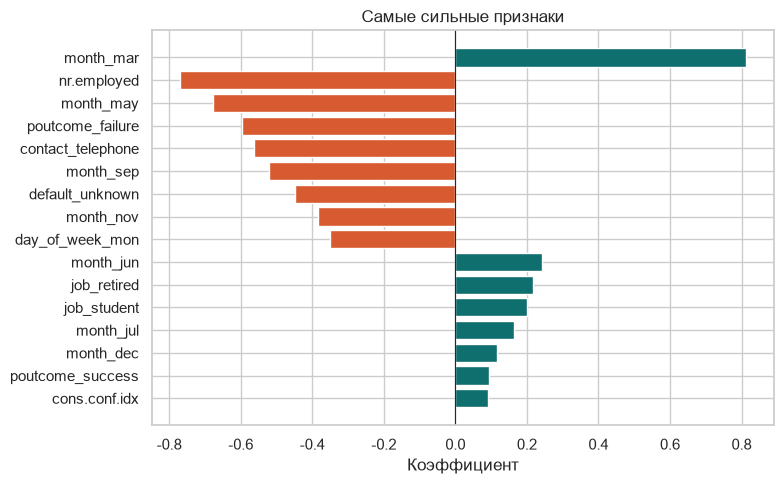

In [39]:
model = LogisticRegression(C=100, max_iter=1000)
model.fit(encoded, y)
coefficients = pd.Series(model.coef_[0], index=encoded.columns)
coefficients.index = [name.split("__", 1)[-1] for name in coefficients.index]
top = pd.concat([coefficients.nsmallest(8), coefficients.nlargest(8)])
top = top.sort_values(key = np.abs, ascending = True)


fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#D85A30" if value < 0 else "#0F6E6E" for value in top]
ax.barh(top.index, top.to_numpy(), color=colors)
ax.axvline(0, color="#1F2933", linewidth=0.8)
ax.set_xlabel("Коэффициент")
ax.set_title("Самые сильные признаки")
fig.tight_layout()
fig.savefig("images/coefficients.png", dpi=150, bbox_inches="tight")



На графике четыре группы.

**Экономический фон.** `nr.employed` (−0.77) — уровень занятости. Чем он ниже, тем чаще берут депозит. 

**Волна обзвона.** `month_mar` (+0.81), `month_may` (−0.68), `month_sep` (−0.52), `month_nov` (−0.38), `month_jun` (+0.24), `month_jul` (+0.16), `month_dec` (+0.11). Месяц без года помечает конкретную волну кампании с её экономическим фоном и составом клиентов, а не «удачный календарный месяц». 

**Прошлая кампания и канал.** `poutcome_failure` (−0.60) — прошлый отказ устойчиво тянет вниз. `contact_telephone` (−0.56) против мобильного — стационарный канал связан с более низкой склонностью.

**Пропуски в `default`.** `default_unknown` (−0.45) — клиент не раскрыл, был ли дефолт по кредиту. Признак ловит отказ делиться данными.

**Кто клиент.** `job_retired` (+0.22) и `job_student` (+0.20) — обе группы чаще среднего говорят «да», но на фоне волны обзвона и экономики это второстепенные сигналы.